# 1 — Exploratory data analysis

**Dataset:** hourly air quality and weather for 134 Pakistani cities,
`data/raw/airquality_hourly.parquet`, tracked by DVC.

This notebook exists to justify the modelling choices made in
`src/features/preprocessing.py`. Every section ends with the design
decision it supports, because an EDA that does not change what you
build afterwards was not worth running.

The file is a DVC pipeline output. If it is missing, restore it with
`dvc pull` rather than re-downloading it — that is the whole point of
versioning it.

In [1]:
# Notebooks live in notebooks/, the package lives at the repo root.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
print("repo root:", ROOT)

repo root: C:\Users\hp\Dropbox\PC (2)\Desktop\One Drive Folder\OneDrive\Projects\Pakistan-AirWatch-AI


In [2]:
from src.config import DATA_CFG, resolve
from src.models.tracking import dataset_version

RAW = resolve(DATA_CFG["paths"]["raw_combined"])
print("path          :", RAW.relative_to(ROOT))
print("exists        :", RAW.exists())
print("dvc md5       :", dataset_version("data/raw/airquality_hourly.parquet"))

df = pd.read_parquet(RAW)
cities = pd.read_csv(resolve(DATA_CFG["cities"]["file"]))

# The raw table is keyed by city_id only; names and provinces live in
# the reference table so the big file never stores repeated strings.
df = df.merge(
    cities[["city_id", "city_name", "province", "population"]],
    on="city_id",
    how="left",
)
print("rows          :", f"{len(df):,}")
print("memory        :", f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

path          : data\raw\airquality_hourly.parquet
exists        : True
dvc md5       : c44c27395799c1bc4df9e44c0d3cef26


rows          : 2,822,112


memory        : 1.13 GB


## 1.1 Coverage

Three questions decide whether this dataset can support a 24-hour
forecast at all: how long is the history, is it unbroken, and is every
city present for all of it.

In [3]:
span = df["timestamp"].agg(["min", "max"])
hours = (span["max"] - span["min"]).total_seconds() / 3600 + 1
per_city = df.groupby("city_id").size()

print(f"first timestamp : {span['min']}")
print(f"last timestamp  : {span['max']}")
print(f"calendar hours  : {hours:,.0f}")
print(f"cities          : {df['city_id'].nunique()}")
print(f"provinces       : {df['province'].nunique()}")
print()
print(f"rows per city   : min {per_city.min():,}  median {per_city.median():,.0f}  max {per_city.max():,}")
print(f"completeness    : {len(df) / (hours * df['city_id'].nunique()) * 100:.2f}% of a full grid")
print()
print(df.groupby("province")["city_id"].nunique().sort_values(ascending=False).to_string())

first timestamp : 2022-08-05 00:00:00+00:00
last timestamp  : 2026-11-24 23:00:00+00:00
calendar hours  : 37,752
cities          : 84


provinces       : 6

rows per city   : min 8,664  median 37,752  max 37,752
completeness    : 88.99% of a full grid



province
Punjab                  33
Khyber Pakhtunkhwa      22
Balochistan             17
Azad Jammu & Kashmir     6
Gilgit-Baltistan         5
Islamabad                1


## 1.2 Missingness

Which columns are usable as features. A column that is mostly absent
cannot be lagged into a useful predictor, and silently filling it
would fabricate signal.

In [4]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
if len(miss):
    print("columns with missing values (%):")
    print(miss.round(3).to_string())
else:
    print("No missing values in any column.")

print()
print("target (pm2_5) missing:", f"{df['pm2_5'].isna().mean() * 100:.4f}%")
print("data_source breakdown:")
print(df["data_source"].value_counts().to_string())

columns with missing values (%):
boundary_layer_height    11.144
pm10                      0.000

target (pm2_5) missing: 0.0000%
data_source breakdown:


data_source
open-meteo    2822112


## 1.3 What the target actually looks like

PM2.5 is strongly right-skewed: most hours are ordinary and a thin
tail carries the episodes that matter for health. The EPA bands are
drawn on so the axis means something clinically, not just numerically.

percentiles (ug/m3):
  p1          2.0
  p25        15.4
  p50        27.5
  p75        45.6


  p90        71.5
  p99       169.5
  p99.9     281.3
  mean      36.2
  max      849.4



skew  2.93   (0 = symmetric)


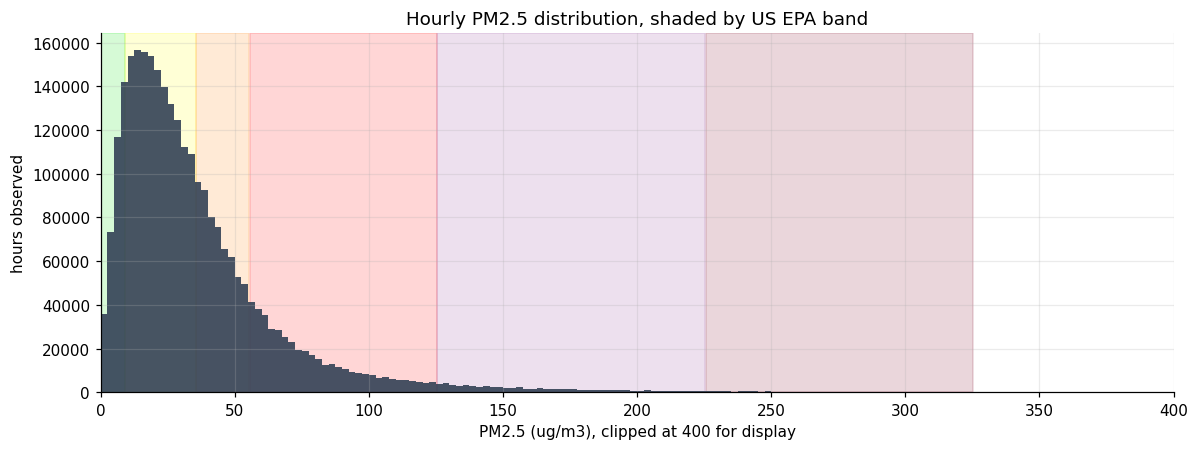


share of all hours by band (%):
pm2_5
Good                              11.15
Moderate                          51.48
Unhealthy for Sensitive Groups    20.08
Unhealthy                         14.76
Very Unhealthy                     2.21
Hazardous                          0.32


In [5]:
from src.serving.aqi import legend

pm = df["pm2_5"].dropna()
bands = legend()

print("percentiles (ug/m3):")
for q in [1, 25, 50, 75, 90, 99, 99.9]:
    print(f"  p{q:<5} {np.percentile(pm, q):8.1f}")
print(f"  mean  {pm.mean():8.1f}")
print(f"  max   {pm.max():8.1f}")
print(f"\nskew  {pm.skew():.2f}   (0 = symmetric)")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.hist(pm.clip(upper=400), bins=160, color="#334155", alpha=0.9)
for b in bands:
    lo, hi = b["pm25_lower"], b["pm25_upper"]
    if lo is None or lo > 400:
        continue
    ax.axvspan(lo, min(hi or 400, 400), color=b["color"], alpha=0.16, zorder=0)
ax.set_xlim(0, 400)
ax.set_xlabel("PM2.5 (ug/m3), clipped at 400 for display")
ax.set_ylabel("hours observed")
ax.set_title("Hourly PM2.5 distribution, shaded by US EPA band")
plt.tight_layout()
plt.show()

share = pd.cut(
    pm,
    bins=[0, 9, 35.4, 55.4, 125.4, 225.4, np.inf],
    labels=[b["name"] for b in bands],
).value_counts(normalize=True).sort_index() * 100
print("\nshare of all hours by band (%):")
print(share.round(2).to_string())

**Design consequence.** The skew is why the model trains with
`objective: reg:absoluteerror` (see `configs/model_params.yaml`) and
is scored on MAE. Squared error would let the thin upper tail dominate
the loss and drag predictions upward for the ordinary hours that make
up most of the data.

## 1.4 Seasonality — the smog season is real

Punjab's winter smog is not folklore: cold air traps emissions under a
shallow inversion layer. If this shows up in the data, month and the
boundary-layer height belong in the feature set.

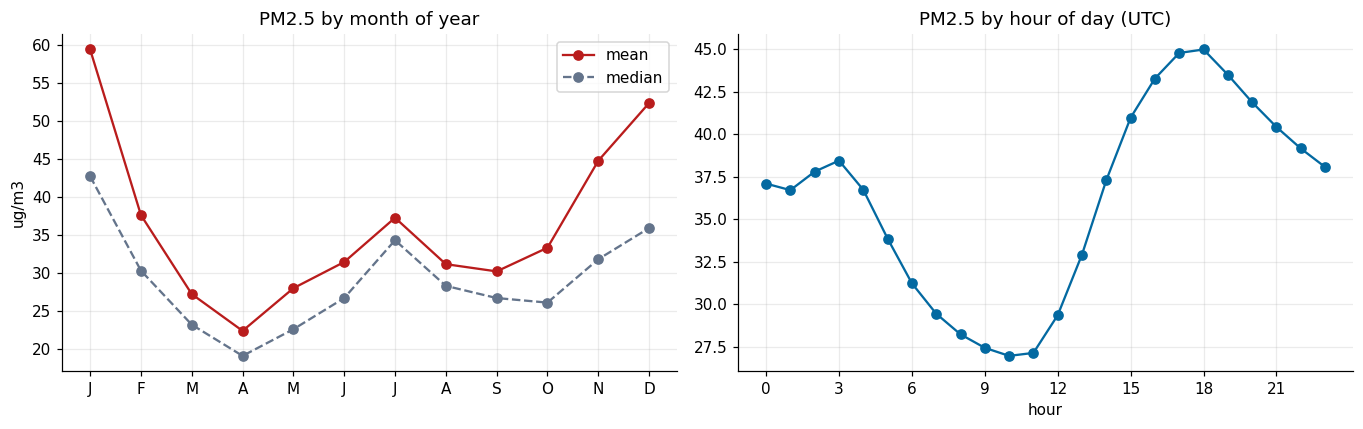

worst month : 1  (59.4 ug/m3)
best  month : 4  (22.4 ug/m3)
ratio       : 2.65x
diurnal swing: 18.0 ug/m3


In [6]:
monthly = df.groupby(df["timestamp"].dt.month)["pm2_5"].agg(["mean", "median"])
hourly = df.groupby(df["timestamp"].dt.hour)["pm2_5"].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4))
a1.plot(monthly.index, monthly["mean"], "o-", color="#b91c1c", label="mean")
a1.plot(monthly.index, monthly["median"], "o--", color="#64748b", label="median")
a1.set_xticks(range(1, 13))
a1.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
a1.set_title("PM2.5 by month of year")
a1.set_ylabel("ug/m3")
a1.legend()

a2.plot(hourly.index, hourly.values, "o-", color="#0369a1")
a2.set_xticks(range(0, 24, 3))
a2.set_title("PM2.5 by hour of day (UTC)")
a2.set_xlabel("hour")
plt.tight_layout()
plt.show()

print(f"worst month : {monthly['mean'].idxmax()}  ({monthly['mean'].max():.1f} ug/m3)")
print(f"best  month : {monthly['mean'].idxmin()}  ({monthly['mean'].min():.1f} ug/m3)")
print(f"ratio       : {monthly['mean'].max() / monthly['mean'].min():.2f}x")
print(f"diurnal swing: {hourly.max() - hourly.min():.1f} ug/m3")

**Design consequence.** Both cycles are strong, so the feature builder
encodes hour and month cyclically (sine/cosine) rather than as raw
integers — hour 23 and hour 0 are adjacent, and an integer feature
would place them 23 apart.

## 1.5 Persistence — why lag features dominate

Air quality is highly autocorrelated: the best naive forecast of the
next hour is this hour. Measuring how fast that correlation decays
tells us which lags are worth computing.

city: abbottabad   observations: 37,752

lag (h)   correlation
     1    0.965  ######################################
     2    0.893  ###################################
     3    0.801  ################################
     6    0.516  ####################
    12    0.295  ###########
    24    0.766  ##############################
    48    0.681  ###########################
    72    0.639  #########################
   168    0.547  #####################


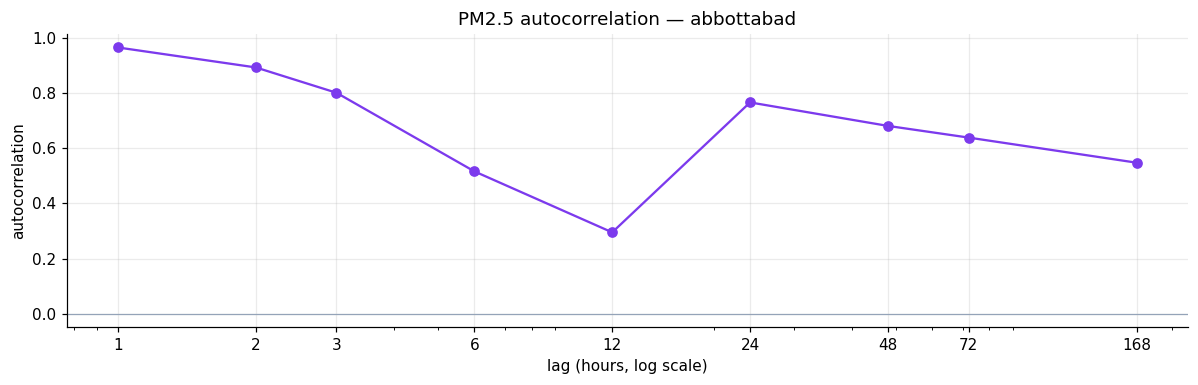

In [7]:
# One well-covered city, so the lag correlation is not an average over
# cities with different gaps.
busiest = df.groupby("city_id").size().idxmax()
s = (
    df[df["city_id"] == busiest]
    .sort_values("timestamp")
    .set_index("timestamp")["pm2_5"]
)
lags = [1, 2, 3, 6, 12, 24, 48, 72, 168]
corr = {lag: s.autocorr(lag) for lag in lags}

print(f"city: {busiest}   observations: {len(s):,}\n")
print("lag (h)   correlation")
for lag, c in corr.items():
    bar = "#" * int(max(c, 0) * 40)
    print(f"{lag:>6}    {c:5.3f}  {bar}")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(list(corr), list(corr.values()), "o-", color="#7c3aed")
ax.axhline(0, color="#94a3b8", lw=0.8)
ax.set_xscale("log")
ax.set_xticks(lags)
ax.set_xticklabels(lags)
ax.set_xlabel("lag (hours, log scale)")
ax.set_ylabel("autocorrelation")
ax.set_title(f"PM2.5 autocorrelation — {busiest}")
plt.tight_layout()
plt.show()

**Design consequence.** This is exactly the lag list in
`configs/model_params.yaml` (`1, 2, 3, 6, 12, 24, 48, 72, 168`). The
24-hour and 168-hour lags are kept even though correlation has decayed
by then, because they carry the daily and weekly cycle rather than raw
persistence.

It is also why the baseline to beat is *persistence*, not the mean. A
model that cannot beat "tomorrow equals today" has learned nothing,
and `src/models/train_baselines.py` logs that baseline for every run
to compare against.

## 1.6 Geography — where the problem is

Two things to establish: which cities carry the burden, and whether
elevation behaves the way the physics predicts (highland cities sit in
thinner, better-ventilated air; the Indus plain traps smog).

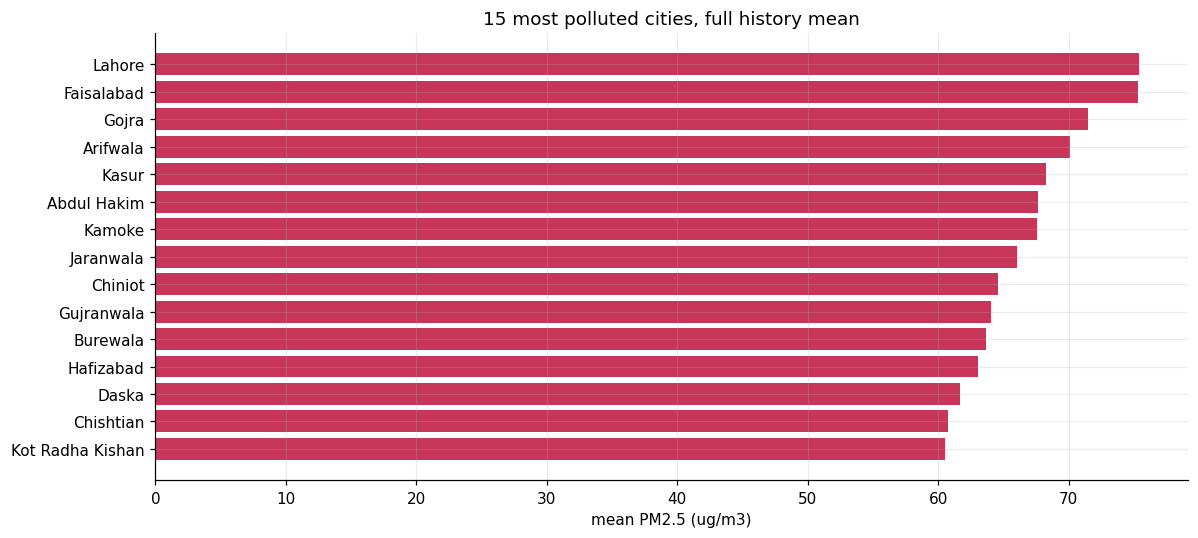

cleanest 5:
city_name           province  pm2_5
   Skardu   Gilgit-Baltistan   12.0
   Gilgit   Gilgit-Baltistan   10.6
   Astore   Gilgit-Baltistan    8.5
    Hunza   Gilgit-Baltistan    7.7
  Chitral Khyber Pakhtunkhwa    6.5

by province:


                           mean     median         max
province                                              
Punjab                57.599998  45.400002  523.400024
Islamabad             38.299999  34.200001  170.899994
Azad Jammu & Kashmir  32.200001  25.400000  280.299988
Khyber Pakhtunkhwa    28.900000  24.500000  271.899994
Balochistan           24.299999  19.299999  849.400024
Gilgit-Baltistan      10.500000   8.400000   92.199997


In [8]:
by_city = (
    df.groupby(["city_id", "city_name", "province"])["pm2_5"]
    .mean()
    .reset_index()
    .sort_values("pm2_5", ascending=False)
)
worst = by_city.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(worst["city_name"], worst["pm2_5"], color="#be123c", alpha=0.85)
ax.set_xlabel("mean PM2.5 (ug/m3)")
ax.set_title("15 most polluted cities, full history mean")
plt.tight_layout()
plt.show()

print("cleanest 5:")
print(by_city.tail(5)[["city_name", "province", "pm2_5"]].round(1).to_string(index=False))
print("\nby province:")
print(
    df.groupby("province")["pm2_5"].agg(["mean", "median", "max"])
    .round(1).sort_values("mean", ascending=False).to_string()
)

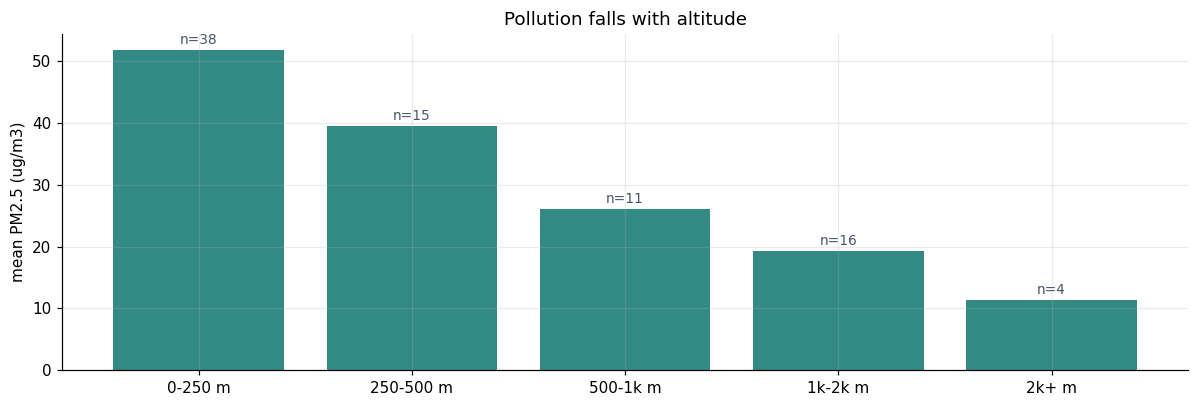

                mean  count
band                       
0-250 m    51.700001     38
250-500 m  39.400002     15
500-1k m   26.100000     11
1k-2k m    19.200001     16
2k+ m      11.300000      4

Spearman correlation elevation vs mean PM2.5: -0.652


In [9]:
elev = (
    df.groupby("city_id")
    .agg(elevation_m=("elevation_m", "first"), pm2_5=("pm2_5", "mean"))
    .dropna()
)
bins = [0, 250, 500, 1000, 2000, 10000]
labels = ["0-250 m", "250-500 m", "500-1k m", "1k-2k m", "2k+ m"]
elev["band"] = pd.cut(elev["elevation_m"], bins=bins, labels=labels, right=False)
profile = elev.groupby("band", observed=True)["pm2_5"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(profile.index.astype(str), profile["mean"], color="#0f766e", alpha=0.85)
for i, (m, n) in enumerate(zip(profile["mean"], profile["count"])):
    ax.text(i, m + 1, f"n={n}", ha="center", fontsize=9, color="#475569")
ax.set_ylabel("mean PM2.5 (ug/m3)")
ax.set_title("Pollution falls with altitude")
plt.tight_layout()
plt.show()

r = elev["elevation_m"].corr(elev["pm2_5"], method="spearman")
print(profile.round(1).to_string())
print(f"\nSpearman correlation elevation vs mean PM2.5: {r:.3f}")

**Design consequence.** Elevation is a static per-city feature in the
model, and the dashboard plots the same relationship (`AltitudeProfile`
in the frontend) because it is one of the few genuinely physical
signals in the dataset — monotonic, explainable, and not an artefact
of sampling.

## Summary

| Finding | What it changed |
|---|---|
| Target is strongly right-skewed | MAE objective and MAE scoring, not RMSE |
| Strong daily and yearly cycles | cyclical hour/month encoding |
| Autocorrelation ~0.9 at 1 h, decaying slowly | the 9-lag + rolling-window feature set |
| Persistence is a hard baseline | every run logs `baseline_mae` to beat |
| Pollution falls with altitude | elevation kept as a static feature |

Next: [02_model_comparison.ipynb](02_model_comparison.ipynb).